<a href="https://colab.research.google.com/github/AdamN5/CampusDatasetProject/blob/main/campus_dataset_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Campus Dataset Project**
Adam Nafea 2026

## Data Preparation
This section loads the campus dataset and prepares it for analysis.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

### Load the Dataset

Raw data from the CSV

In [ ]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows = 4
    )

Inspect the dataset structure...

Below shows data tyoes and a sample of data before we start cleaning and encoding.

In [ ]:
print("Column names")
print(df.dtypes)

print("\nSample rows\n")
print(df.head())

Column names
recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature_

Below is to set the limits of what will be shown when we display the data frame, in this case we dont want any cut offs we want to show every row and column in the table so we can clean them easier later.

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


pd.set_option('display.max_colwidth', None)

display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,NaN,NaN,NaN,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,NaN,NaN,NaN,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,NaN,NaN,NaN,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,NaN,NaN,NaN,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,NaN,NaN,NaN,NaN
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush,NaN,NaN,NaN,NaN
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,NaN,NaN,NaN,NaN,NaN
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,NaN,NaN,NaN,NaN,NaN
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,NaN,NaN,NaN,NaN,NaN
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,NaN,NaN,NaN,NaN,NaN


### Cleaning the Data
Initial clean of data getting rid of unused rows or columns


I noticed there were some blank rows in the middle and end of the sheet, also there were unamed columns that were not being used.

Since the original excel sheet had extra IDs in the ID column but no additional data I decided to use the the location as the data would be more or less useless without the location.

I got rid of the unamed columns by just dropping columns with Unamed.

In [ ]:
df = df.dropna(subset=["location"])

df = df.drop(columns=df.columns[df.columns.str.contains('Unnamed')])

display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,NaN
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,NaN
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,NaN
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,NaN


### Temperature Data Clean

I noticed for the temperature some poeople had put in 'C' after the number for the temperature and some also used decimals.

To solve this I used the function below to replace the C with blankspace and to make all value type a float to accomate the decimals.

In [ ]:
df["temperature_c"] = df["temperature_c"].astype(str).str.replace("C", "").astype(float)

display(df[["recorder_id", "temperature_c"]])

,recorder_id,temperature_c
0,R26_001,16.0
1,R26_001,16.0
2,R26_001,16.0
3,R26_001,16.0
4,R26_001,16.0
5,R26_002,17.0
6,R26_002,17.0
7,R26_002,19.0
8,R26_002,16.0
9,R26_002,18.0


### Categorical cleaning

In [ ]:
# 1. Standardize capitalization
df['weather'] = df['weather'].str.capitalize()
df['foot_traffic'] = df['foot_traffic'].str.capitalize()

# 2. Correct typos in ease_rating
df['ease_rating'] = df['ease_rating'].replace({
    'Vey easy': 'Very easy',
    'Slighly uneasy': 'Slightly uneasy'
})

# 3. Standardize similar ratings
df['nature_connection_experience_rating'] = df['nature_connection_experience_rating'].replace({
    'same': 'No change'
})

# Check the results
for col in ['weather', 'foot_traffic', 'ease_rating', 'nature_connection_experience_rating']:
    print(f"--- Cleaned '{col}' uniqueness ---")
    print(df[col].unique())
    print()

--- Cleaned 'weather' uniqueness ---
['Partly cloudy' 'Sunny' 'Windy' 'Cloudy']

--- Cleaned 'foot_traffic' uniqueness ---
['Low' 'Moderate' 'High']

--- Cleaned 'ease_rating' uniqueness ---
['Neutral' 'Easy' 'Very easy' 'Very uneasy' 'Slightly uneasy']

--- Cleaned 'nature_connection_experience_rating' uniqueness ---
['Less connected' 'A little more connected' 'No change'
 'Much more connected']



### Encoding

#### Data inspection before encoding

In [ ]:
categorical_cols = [
    'weather', 'sound level', 'foot_traffic',
    'wellbeing_rating', 'ease_rating', 'stress_rating',
    'nature_connection_experience_rating'
]

for col in categorical_cols:
    if col in df.columns:
        print(f"--- Value counts for '{col}' (Total Nulls: {df[col].isnull().sum()}) ---")
        print(df[col].value_counts(dropna=False))
        print("\n")

--- Value counts for 'weather' (Total Nulls: 0) ---
weather
Sunny            84
Partly cloudy    36
Cloudy            7
Windy             4
Name: count, dtype: int64


--- Value counts for 'sound level' (Total Nulls: 0) ---
sound level
Moderate    58
Quiet       57
Loud        16
Name: count, dtype: int64


--- Value counts for 'foot_traffic' (Total Nulls: 0) ---
foot_traffic
Low         94
Moderate    24
High        13
Name: count, dtype: int64


--- Value counts for 'wellbeing_rating' (Total Nulls: 0) ---
wellbeing_rating
Positive wellbeing         67
Neutral                    37
Very positive wellbeing    18
Low wellbeing               7
Very low wellbeing          2
Name: count, dtype: int64


--- Value counts for 'ease_rating' (Total Nulls: 0) ---
ease_rating
Easy               56
Neutral            36
Very easy          23
Slightly uneasy    15
Very uneasy         1
Name: count, dtype: int64


--- Value counts for 'stress_rating' (Total Nulls: 0) ---
stress_rating
Mostly calm   

Data encoding

#### Foot Traffic Encoding

In [ ]:
foot_traffic_map = {
    'Low': 1,
    'Moderate': 2,
    'High': 3
}

df['foot_traffic_encoded'] = df['foot_traffic'].map(foot_traffic_map)

#### Wellbeing encoding

In [ ]:
wellbeing_map = {
    'Very low wellbeing': 1,
    'Low wellbeing': 2,
    'Neutral': 3,
    'Positive wellbeing': 4,
    'Very positive wellbeing': 5
}

df['wellbeing_rating_encoded'] = df['wellbeing_rating'].map(wellbeing_map)

#### Ease encoding

In [ ]:
ease_map = {
    'Very uneasy': 1,
    'Slightly uneasy': 2,
    'Neutral': 3,
    'Easy': 4,
    'Very easy': 5
}

df['ease_rating_encoded'] = df['ease_rating'].map(ease_map)

#### Stress encoding

In [ ]:
stress_map = {
    'Very calm': 1,
    'Mostly calm': 2,
    'Neutral': 3,
    'Stressful': 4,
    'Very stressful': 5
}

df['stress_rating_encoded'] = df['stress_rating'].map(stress_map)

#### Connection to nature encoding

In [ ]:
nature_conn_map = {
    'Less connected': 1,
    'No change': 2,
    'A little more connected': 3,
    'Much more connected': 4
}

df['nature_connection_encoded'] = df['nature_connection_experience_rating'].map(nature_conn_map)

#### Sound level encoding

In [ ]:
sound_map = {'Quiet': 1, 'Moderate': 2, 'Loud': 3}
df['sound_level_encoded'] = df['sound level'].str.strip().map(sound_map)
df['sound_level_encoded'].value_counts()

,count
sound_level_encoded,
2,58
1,57
3,16


#### Trees presence encoding

In [ ]:
trees_map = {
    'None': 0,
    'One or two': 1,
    'Many': 2
}

df['trees_presence_encoded'] = df['trees_presence'].fillna('None').astype(str).str.strip().map(trees_map)
df['trees_presence_encoded'].value_counts(dropna=False)

,count
trees_presence_encoded,
2,99
1,28
0,4


#### Plant pressence encoding

In [ ]:
plant_map = {
    'None': 0,
    'Some': 1,
    'Many': 2
}

plant_cols = [
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence'
]

for col in plant_cols:
    encoded_col = f"{col}_encoded"
    df[encoded_col] = df[col].fillna('None').astype(str).str.strip().map(plant_map)
    print(f"--- Value counts for {encoded_col} ---")
    print(df[encoded_col].value_counts(dropna=False))
    print()

--- Value counts for native_or_wild_plant_presence_encoded ---
native_or_wild_plant_presence_encoded
1    77
2    44
0    10
Name: count, dtype: int64

--- Value counts for ornnamental_or_planted_plant_presence_encoded ---
ornnamental_or_planted_plant_presence_encoded
1    60
2    37
0    34
Name: count, dtype: int64

--- Value counts for moss_or_lichen_presence_encoded ---
moss_or_lichen_presence_encoded
1    63
0    35
2    33
Name: count, dtype: int64



#### Table

In [ ]:
display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,foot_traffic_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded,sound_level_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,1,4,3,4,1,1,2,1,1,1
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,1,4,3,3,3,2,2,0,1,0
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,1,4,4,2,2,1,2,0,2,1
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,1,4,3,3,4,2,1,1,0,1
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,1,4,4,2,1,2,1,0,1,0
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17.0,Moderate,Low,Traffic,Human voices,Other birds,Insects,2.0,4.0,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush,1,4,4,2,3,2,2,1,1,2
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17.0,Moderate,Low,Traffic,Other,Wind,Insects,2.0,2.0,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,NaN,1,3,3,1,2,2,2,1,2,1
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19.0,Moderate,Low,Traffic,Service machinery,Wind,Other,7.0,0.0,Many,Many,Many,Many,Positive wellbeing,Very easy,Mostly calm,Much more connected,wild plants,NaN,1,4,5,2,4,2,2,2,2,2
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16.0,Quiet,Low,Traffic,Human voices,Wind,Trees,3.0,1.0,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,NaN,1,3,3,1,1,1,2,2,2,1
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18.0,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6.0,2.0,Many,Many,Many,Some,Very positive wellbeing,Very easy,Very calm,Much more connected,insects,NaN,1,5,5,1,4,1,2,2,2,1


## Data Analysis

### Data Overview

Data is cleaned and encoded, so its ready for analysis.

In [ ]:
df.head()

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,foot_traffic_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded,sound_level_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,1,4,3,4,1,1,2,1,1,1
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,1,4,3,3,3,2,2,0,1,0
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,1,4,4,2,2,1,2,0,2,1
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,1,4,3,3,4,2,1,1,0,1
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,1,4,4,2,1,2,1,0,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131 entries, 0 to 133
Data columns (total 33 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   recorder_id                                    131 non-null    object 
 1   date                                           131 non-null    object 
 2   location                                       131 non-null    object 
 3   weather                                        131 non-null    object 
 4   temperature_c                                  131 non-null    float64
 5   sound level                                    131 non-null    object 
 6   foot_traffic                                   131 non-null    object 
 7   primary_sound_type_urban                       131 non-null    object 
 8   other_sound_type_urban                         128 non-null    object 
 9   primary_sound_type_nature                      131 non-null

### Summary Statistics

Used to summarise a set of observations to show central tendency and spread of numeric values and frequency in every category.

#### Numeric summary

In [ ]:
df.describe()

,temperature_c,insects_count,birds_count,foot_traffic_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded,sound_level_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,16.812977,2.793893,2.045802,1.381679,3.702290,3.648855,2.175573,2.572519,1.687023,1.725191,1.259542,1.022901,0.984733
std,0.892998,5.167528,2.814421,0.661676,0.829223,0.927558,0.854679,1.037975,0.680316,0.512211,0.589495,0.738665,0.723078
min,13.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,0.000000,0.000000,1.000000,3.000000,3.000000,2.000000,2.000000,1.000000,2.000000,1.000000,0.000000,0.000000
50%,17.000000,1.000000,1.000000,1.000000,4.000000,4.000000,2.000000,3.000000,2.000000,2.000000,1.000000,1.000000,1.000000
75%,17.000000,3.000000,3.000000,2.000000,4.000000,4.000000,3.000000,3.000000,2.000000,2.000000,2.000000,2.000000,1.500000
max,19.000000,31.000000,20.000000,3.000000,5.000000,5.000000,5.000000,4.000000,3.000000,2.000000,2.000000,2.000000,2.000000


#### Category counts

In [ ]:
cat_cols = ['weather', 'sound level', 'foot_traffic', 'trees_presence',
            'wellbeing_rating', 'ease_rating', 'stress_rating',
            'nature_connection_experience_rating']
for col in cat_cols:
    print(df[col].value_counts(dropna=False), '\n')

weather
Sunny            84
Partly cloudy    36
Cloudy            7
Windy             4
Name: count, dtype: int64 

sound level
Moderate    58
Quiet       57
Loud        16
Name: count, dtype: int64 

foot_traffic
Low         94
Moderate    24
High        13
Name: count, dtype: int64 

trees_presence
Many          99
One or two    28
NaN            4
Name: count, dtype: int64 

wellbeing_rating
Positive wellbeing         67
Neutral                    37
Very positive wellbeing    18
Low wellbeing               7
Very low wellbeing          2
Name: count, dtype: int64 

ease_rating
Easy               56
Neutral            36
Very easy          23
Slightly uneasy    15
Very uneasy         1
Name: count, dtype: int64 

stress_rating
Mostly calm       58
Neutral           37
Very calm         29
Stressful          6
Very stressful     1
Name: count, dtype: int64 

nature_connection_experience_rating
A little more connected    42
No change                  35
Much more connected        29
L

#### Records per location

In [ ]:
df['location'].value_counts()

,count
location,
L06 HedgingBehindSportsCentre,27
L01 MainEntrance,22
L05 GreenFrontSportsCentre,19
L04 PathFrontiHub,18
L07 CarParkNearSportsCentre,15
L02 LibraryGreen,14
L03 LowerSidePathiHub,9
L08 AccessRoadNearSportsCentre,7


### Distribution

Distributions can show how the variables are spread which can help show the skew, outliers and imbalance.

#### Records per localation

Shows how many record collected at each location.

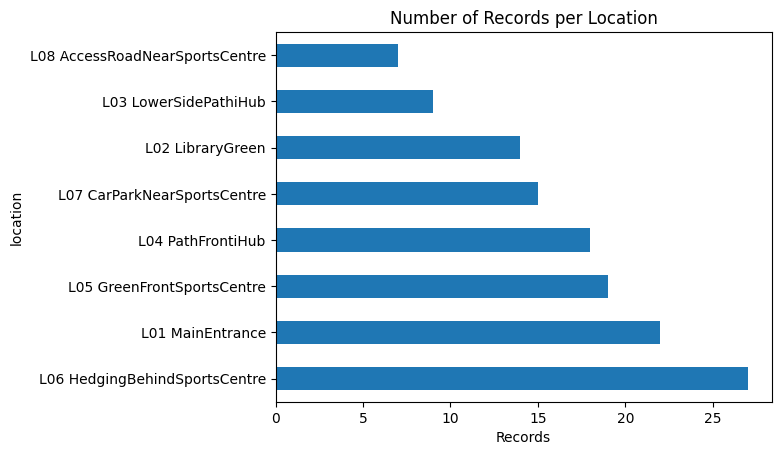

In [ ]:
df['location'].value_counts().plot(kind='barh')
plt.title('Number of Records per Location')
plt.xlabel('Records')
plt.show()

#### Experience scores

Shows experience ratings with stress skewing low and with wellbeing and ease skewing high.

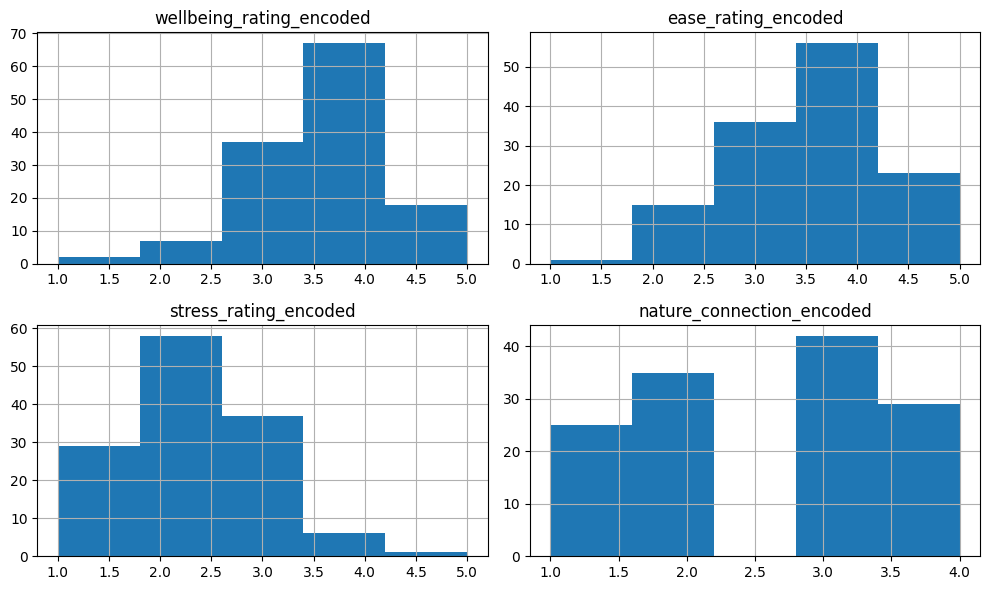

In [ ]:
score_cols = ['wellbeing_rating_encoded', 'ease_rating_encoded',
              'stress_rating_encoded', 'nature_connection_encoded']

df[score_cols].hist(bins=5, figsize=(10, 6))
plt.tight_layout()
plt.show()

#### Enviroment counts

Shows the spread of enviroment scores.

Temperature, insect and bird counts being similar.

Weather skews mostly sunny, while sound level is mostly quiet and moderate, foot traffic is mostly low while tree presence skews to many.

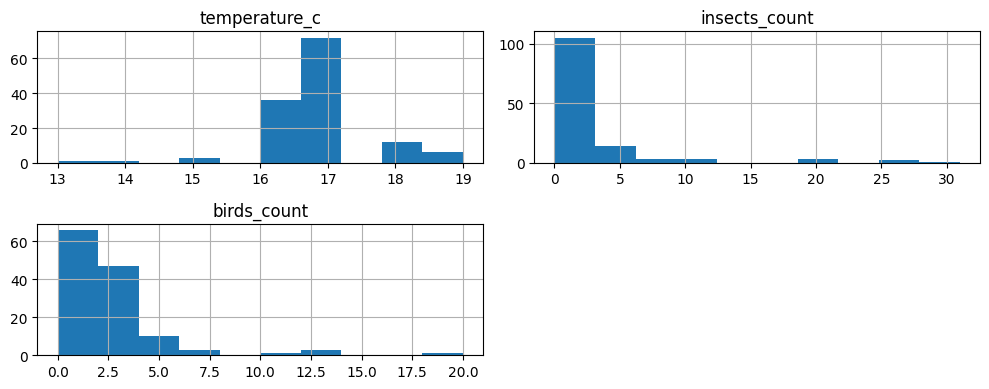

In [ ]:
df[['temperature_c', 'insects_count', 'birds_count']].hist(bins=10, figsize=(10, 4))
plt.tight_layout()
plt.show()

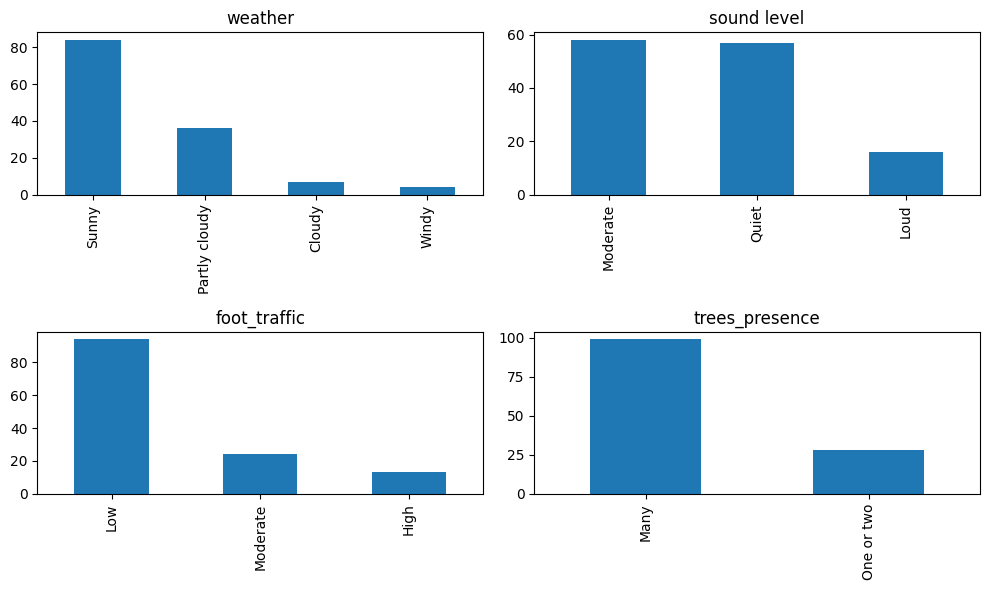

In [ ]:
env_cols = ['weather', 'sound level', 'foot_traffic', 'trees_presence']

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flatten(), env_cols):
    df[col].value_counts().plot(kind='bar', ax=ax, title=col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

### Relationships and Correlation

Shows how the envirmomental values relate to the experience people had.
We will show this by using a correlation matrix and group comparisons.

Correlation shows the the strength of relationships but correlation does not prove causation.

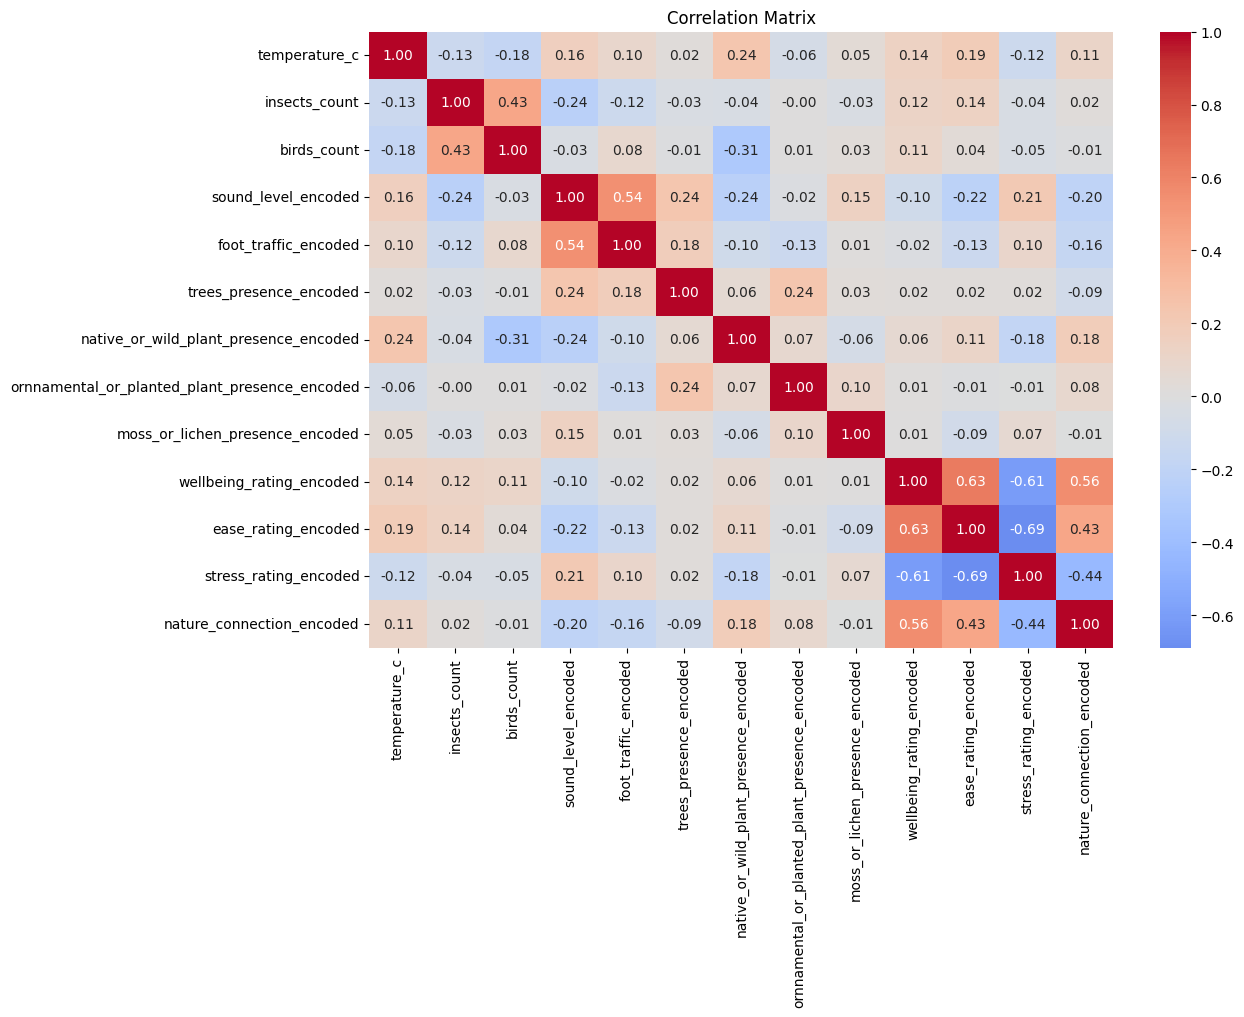

In [ ]:
corr_cols = ['temperature_c', 'insects_count', 'birds_count',
             'sound_level_encoded', 'foot_traffic_encoded', 'trees_presence_encoded',
             'native_or_wild_plant_presence_encoded',
             'ornnamental_or_planted_plant_presence_encoded',
             'moss_or_lichen_presence_encoded',
             'wellbeing_rating_encoded', 'ease_rating_encoded',
             'stress_rating_encoded', 'nature_connection_encoded']

plt.figure(figsize=(12, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

Experience rating are strongly related to each other.

Wellbeing and ease are positivly correlated while stress is negativly correlated with both.

There is also a positive correlation between the foot traffic and noise. Louder locations have a slightly lower ease and nature connection while having a higher stress.

#### Experience by sound level

Compares the average experience ratings accross quiet, moderate and loud locations to see whether sound affects ratings.

In [ ]:
exp_cols = ['wellbeing_rating_encoded', 'ease_rating_encoded',
            'stress_rating_encoded', 'nature_connection_encoded']

df.groupby('sound level')[exp_cols].mean().round(2)

,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded
sound level,,,,
Loud,3.50,3.31,2.50,1.88
Moderate,3.69,3.52,2.28,2.64
Quiet,3.77,3.88,1.98,2.70


#### Experience by foot traffic

Compares the average experience ratings across high, moderate and low foot traffic locations to see whether it affects ratings.

In [ ]:
df.groupby('foot_traffic')[exp_cols].mean().round(2)

,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded
foot_traffic,,,,
High,3.69,3.31,2.38,2.31
Low,3.71,3.71,2.13,2.69
Moderate,3.67,3.58,2.25,2.25


### K-Means clustering

#### Feature selection and scaling
When picking features for k-means clustering I tried to pick ones that might corrolate with each other.

In [ ]:
feature_cols = ['insects_count', 'birds_count',
                'sound_level_encoded', 'foot_traffic_encoded',
                'trees_presence_encoded',
                'native_or_wild_plant_presence_encoded',
                'ornnamental_or_planted_plant_presence_encoded',
                'moss_or_lichen_presence_encoded']

X = df[feature_cols]
X_scaled = StandardScaler().fit_transform(X)

Above I picked

#### Choosing k

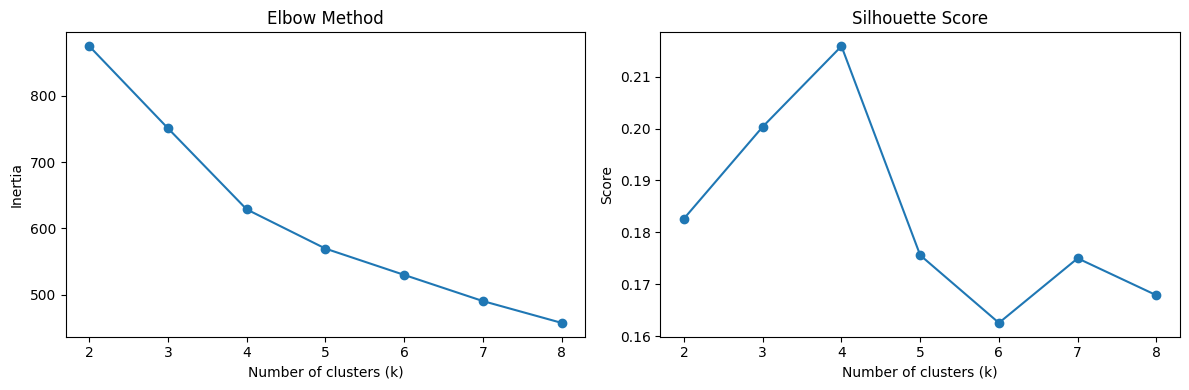

In [ ]:
k_values = range(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[1].plot(k_values, silhouettes, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

#### Fitting K and cluster profiles

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

df['cluster'].value_counts().sort_index()

,count
cluster,
0,27
1,6
2,30
3,68


In [ ]:
df.groupby('cluster')[feature_cols].mean().round(2)

,insects_count,birds_count,sound_level_encoded,foot_traffic_encoded,trees_presence_encoded,native_or_wild_plant_presence_encoded,ornnamental_or_planted_plant_presence_encoded,moss_or_lichen_presence_encoded
cluster,,,,,,,,
0,1.96,1.78,1.37,1.15,0.85,1.22,0.63,0.96
1,19.00,11.00,1.00,1.17,1.50,0.67,1.33,0.83
2,1.13,2.37,2.43,2.43,1.93,1.03,0.87,1.03
3,2.43,1.22,1.54,1.03,2.00,1.43,1.22,0.99


In [ ]:
df.groupby('cluster')[exp_cols].mean().round(2)

,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded,nature_connection_encoded
cluster,,,,
0,3.63,3.63,2.15,2.63
1,4.17,4.00,2.00,2.83
2,3.63,3.33,2.37,2.23
3,3.72,3.76,2.12,2.68
